# Zero-Shot Classification of Amazon Product Reviews with OpenAI Embeddings

This notebook builds a classifier for Amazon product reviews **without any labeled training data**, following the OpenAI Cookbook example
[*Zero-shot classification with embeddings*](https://developers.openai.com/cookbook/examples/zero-shot_classification_with_embeddings).

**Idea:** embed every review and a short text description of every class, then assign each review to the class whose description embedding is most similar (cosine similarity). The model never sees a labeled example.

**What we build**

1. **Binary sentiment** (positive / negative), as in the cookbook, comparing plain label names vs. descriptive label prompts.
2. **Three-class sentiment** (negative / neutral / positive), adding the 3-star reviews back in.
3. **Topic categories** (taste, price, packaging/shipping, health, pets, …) so reviews can be grouped by *what* customers talk about, then crossed with sentiment.
4. A **supervised baseline** (logistic regression on the same embeddings) to show how far zero-shot gets compared with a model that does use labels.
5. A reusable `classify_review()` function for new reviews.

**Dataset:** 1,000 Amazon Fine Food reviews (Score 1–5) with precomputed `text-embedding-3-small` embeddings, from the OpenAI Cookbook repository.

## 1. Setup

In [1]:
# %pip install -q openai python-dotenv pandas numpy scikit-learn matplotlib

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
from dotenv import load_dotenv
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, accuracy_score, f1_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Load OPENAI_API_KEY from the .env file next to this notebook
load_dotenv()
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found - add it to .env"
client = OpenAI()

# Must match the model used to embed the reviews in the dataset
EMBEDDING_MODEL = "text-embedding-3-small"

## 2. Load the reviews

The CSV already contains an `embedding` column computed with `text-embedding-3-small` on the `combined` field (`Title: <summary>; Content: <text>`), so we only need to call the API for the short class descriptions.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/openai/openai-cookbook/main/examples/data/fine_food_reviews_with_embeddings_1k.csv"
DATA_PATH = "data/fine_food_reviews_with_embeddings_1k.csv"

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH, index_col=0)
# Embeddings are stored as strings like "[0.01, -0.02, ...]"
df["embedding"] = df["embedding"].apply(lambda s: np.array(eval(s), dtype=np.float32))

print(df.shape)
df[["ProductId", "Score", "Summary", "Text"]].head()

(1000, 8)


,ProductId,Score,Summary,Text
Unnamed: 0,,,,
0,B003XPF9BO,5,where does one start...and stop... with a tre...,Wanted to save some to bring to my Chicago fam...
297,B003VXHGPK,4,"Good, but not Wolfgang Puck good","Honestly, I have to admit that I expected a li..."
296,B008JKTTUA,1,Should advertise coconut as an ingredient more...,"First, these should be called Mac - Coconut ba..."
295,B000LKTTTW,5,Best tomato soup,I have a hard time finding packaged food of an...
294,B001D09KAM,1,Should advertise coconut as an ingredient more...,"First, these should be called Mac - Coconut ba..."


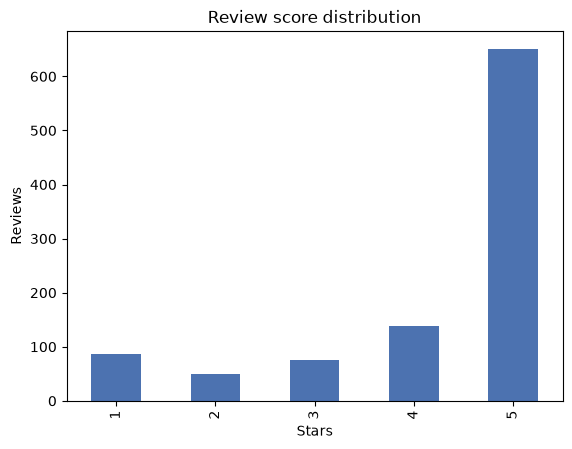

In [4]:
ax = df["Score"].value_counts().sort_index().plot.bar(color="#4C72B0", title="Review score distribution")
ax.set_xlabel("Stars"); ax.set_ylabel("Reviews"); plt.show()

The data is heavily skewed toward 5-star reviews. Following the cookbook, for the binary task we map **1–2 stars → negative**, **4–5 stars → positive**, and drop the neutral 3-star reviews.

In [5]:
def score_to_sentiment(score):
    if score <= 2:
        return "negative"
    if score == 3:
        return "neutral"
    return "positive"

df["sentiment"] = df["Score"].apply(score_to_sentiment)
binary_df = df[df["sentiment"] != "neutral"].copy()
binary_df["sentiment"].value_counts()

sentiment
positive    789
negative    136
Name: count, dtype: int64

## 3. Embedding and similarity helpers

In [6]:
def get_embeddings(texts, model=EMBEDDING_MODEL):
    """Embed a list of strings in one API call; returns an (n, d) array."""
    texts = [t.replace("\n", " ") for t in texts]
    response = client.embeddings.create(input=texts, model=model)
    return np.array([d.embedding for d in response.data], dtype=np.float32)


def cosine_similarity_matrix(a, b):
    """Cosine similarity between every row of a and every row of b."""
    a = a / np.linalg.norm(a, axis=1, keepdims=True)
    b = b / np.linalg.norm(b, axis=1, keepdims=True)
    return a @ b.T


def zero_shot_classify(review_embeddings, label_descriptions):
    """Assign each review to the label whose description embedding is most similar.

    label_descriptions: dict {label: description text}
    Returns (predicted labels, similarity matrix of shape (n_reviews, n_labels)).
    """
    labels = list(label_descriptions)
    label_embeddings = get_embeddings(list(label_descriptions.values()))
    sims = cosine_similarity_matrix(review_embeddings, label_embeddings)
    preds = np.array(labels)[sims.argmax(axis=1)]
    return preds, sims


def evaluate(y_true, y_pred, labels, title):
    print(title)
    print(classification_report(y_true, y_pred, labels=labels, digits=3))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", colorbar=False)
    plt.title(title); plt.show()


X_binary = np.vstack(binary_df["embedding"].values)

## 4. Binary sentiment (zero-shot)

### 4a. Plain label names
First, embed just the words `"negative"` and `"positive"`.

Binary sentiment – plain label names
              precision    recall  f1-score   support

    negative      0.541     0.919     0.681       136
    positive      0.984     0.866     0.921       789

    accuracy                          0.874       925
   macro avg      0.763     0.892     0.801       925
weighted avg      0.919     0.874     0.886       925



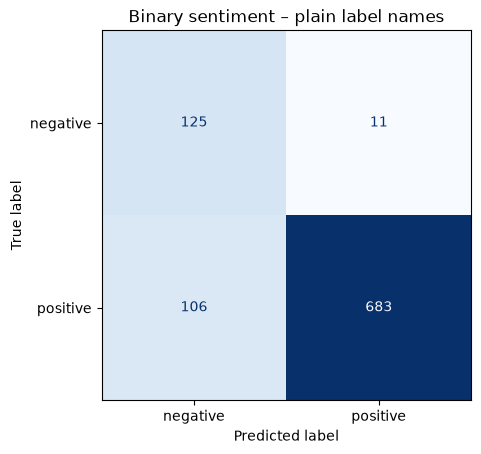

In [7]:
plain_labels = {"negative": "negative", "positive": "positive"}
preds, sims = zero_shot_classify(X_binary, plain_labels)
evaluate(binary_df["sentiment"], preds, ["negative", "positive"], "Binary sentiment – plain label names")

### 4b. Descriptive label prompts
The cookbook shows that describing the class in a sentence that resembles the data improves results considerably: the label embedding lands closer to the region of embedding space where real reviews live.

Binary sentiment – descriptive labels
              precision    recall  f1-score   support

    negative      0.757     0.963     0.848       136
    positive      0.993     0.947     0.970       789

    accuracy                          0.949       925
   macro avg      0.875     0.955     0.909       925
weighted avg      0.959     0.949     0.952       925



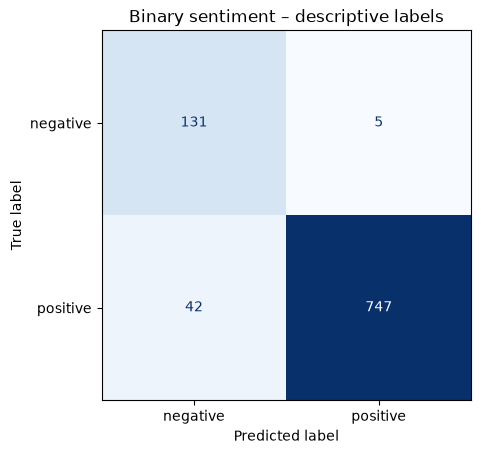

In [8]:
binary_labels = {
    "negative": "An Amazon review with a negative sentiment.",
    "positive": "An Amazon review with a positive sentiment.",
}
preds, sims = zero_shot_classify(X_binary, binary_labels)
binary_df["zero_shot"] = preds
evaluate(binary_df["sentiment"], preds, ["negative", "positive"], "Binary sentiment – descriptive labels")

### 4c. Precision–recall and choosing a threshold
Using `sim(positive) − sim(negative)` as a continuous score lets us trade precision against recall instead of using a fixed argmax. Because the data is imbalanced (≈85% positive), shifting the threshold often helps the negative class.

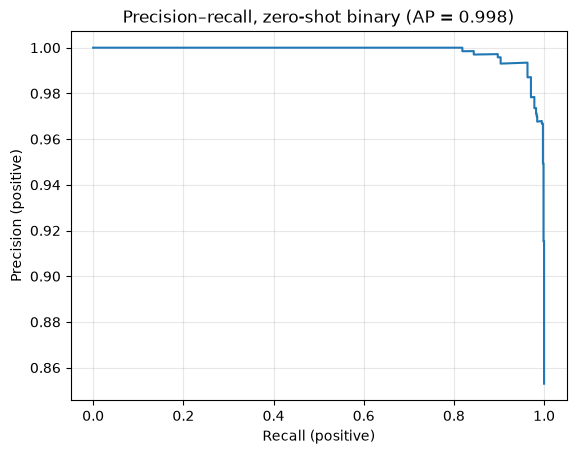

Best threshold: -0.0479  (macro-F1 0.932 vs. 0.909 at 0)
Binary sentiment – tuned threshold
              precision    recall  f1-score   support

    negative      0.982     0.801     0.883       136
    positive      0.967     0.997     0.982       789

    accuracy                          0.969       925
   macro avg      0.974     0.899     0.932       925
weighted avg      0.969     0.969     0.967       925



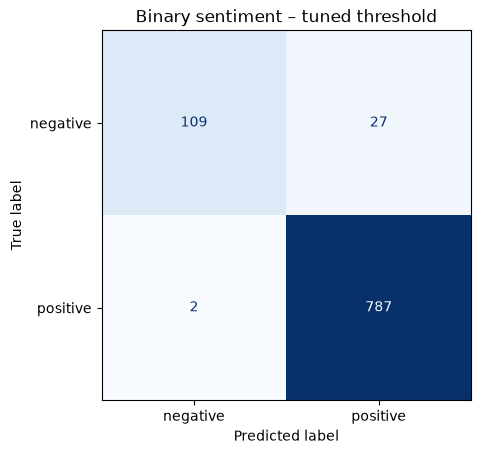

In [9]:
binary_df["pos_score"] = sims[:, 1] - sims[:, 0]
y_true_bin = (binary_df["sentiment"] == "positive").astype(int)

precision, recall, thresholds = precision_recall_curve(y_true_bin, binary_df["pos_score"])
ap = average_precision_score(y_true_bin, binary_df["pos_score"])

plt.plot(recall, precision)
plt.xlabel("Recall (positive)"); plt.ylabel("Precision (positive)")
plt.title(f"Precision–recall, zero-shot binary (AP = {ap:.3f})"); plt.grid(alpha=.3); plt.show()

# Pick the threshold that maximises macro-F1 (in practice, tune this on a small held-out labeled set)
candidates = np.quantile(binary_df["pos_score"], np.linspace(0.01, 0.5, 50))
f1s = [f1_score(y_true_bin, binary_df["pos_score"] > t, average="macro") for t in candidates]
best_t = candidates[int(np.argmax(f1s))]
print(f"Best threshold: {best_t:.4f}  (macro-F1 {max(f1s):.3f} vs. {f1_score(y_true_bin, binary_df['pos_score'] > 0, average='macro'):.3f} at 0)")

tuned = np.where(binary_df["pos_score"] > best_t, "positive", "negative")
evaluate(binary_df["sentiment"], tuned, ["negative", "positive"], "Binary sentiment – tuned threshold")

### Where does it go wrong?

In [10]:
errors = binary_df[binary_df["zero_shot"] != binary_df["sentiment"]]
pd.set_option("display.max_colwidth", 200)
errors[["Score", "sentiment", "zero_shot", "Summary", "Text"]].head(8)

,Score,sentiment,zero_shot,Summary,Text
Unnamed: 0,,,,,
297,4,positive,negative,"Good, but not Wolfgang Puck good","Honestly, I have to admit that I expected a little better. That's not to say that this is bad coffee - in fact it's quite bold without being too acidic, and pretty satisfying overall. I think my m..."
289,1,negative,positive,Cute,"For some reason I thought that you got three ""pops"" but you only get one. For the price I paid for the Puff Pop and shipping it was just a little too much. Everyone laughed at it and thought it ..."
278,5,positive,negative,"Great coffee, not bitter.","I'm not a big fan of the green mountain coffees, because they all seem to be bitter. This is a nice brew that is strong enough for me without being bitter. Their version of the K cup works great..."
318,4,positive,negative,yummy cookies!,We've ordered for them every month and only once the package inside the seal had a small hole and wasn't as fresh.
242,4,positive,negative,yummy cookies!,We've ordered for them every month and only once the package inside the seal had a small hole and wasn't as fresh.
233,4,positive,negative,Good quality grinder,"I had become almost addicted to the garlic and sea salt grinder that the Dollar Tree used to sell. Of course, (as is the case with almost everything they sell that I really like) they quit carryin..."
224,2,negative,positive,"Paw Flapper Fun, But Too Easy","I got my dog the Paw Flapper because he's a Basset Hound mix and loves to use his nose. He's also pretty smart, so keeping him occupied can be difficult. Unfortunately, this is a super simple puzz..."
246,5,positive,negative,"Love it, or not so much","As my title says, you either will love it or not. I love it, some friends who tried it and didnt like it were disapointed the flavor didnt quite match the aroma. This is one you will have to try f..."


## 5. Three-class sentiment (negative / neutral / positive)

Now we keep all 1,000 reviews. Neutral (3-star) reviews are the hardest: they usually mix praise and complaints, so we describe that explicitly.

Three-class sentiment – zero-shot
              precision    recall  f1-score   support

    negative      0.724     0.831     0.774       136
     neutral      0.169     0.760     0.277        75
    positive      0.986     0.634     0.772       789

    accuracy                          0.670      1000
   macro avg      0.627     0.742     0.607      1000
weighted avg      0.889     0.670     0.735      1000



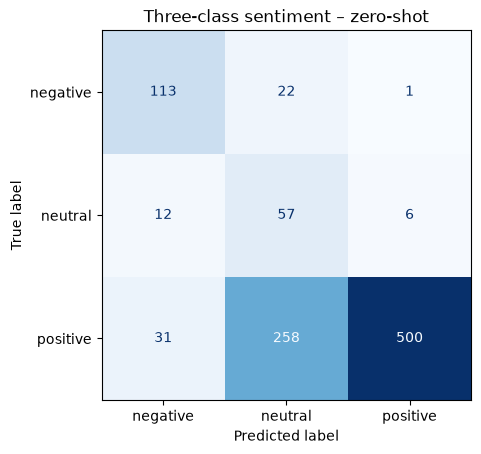

In [11]:
three_labels = {
    "negative": "An Amazon review with a negative sentiment. The customer is unhappy and would not recommend the product.",
    "neutral": "An Amazon review with a mixed, neutral sentiment. The product is okay or average, with both good and bad points.",
    "positive": "An Amazon review with a positive sentiment. The customer loves the product and recommends it.",
}
X_all = np.vstack(df["embedding"].values)
preds3, sims3 = zero_shot_classify(X_all, three_labels)
df["zero_shot_3"] = preds3
evaluate(df["sentiment"], preds3, ["negative", "neutral", "positive"], "Three-class sentiment – zero-shot")

## 6. Topic categories: *what* are customers talking about?

Sentiment tells us *how* customers feel; topic tells us *why*. There is no ground truth for topics in this dataset, so this is an exploratory, fully unsupervised categorization. Each review gets its single most similar topic.

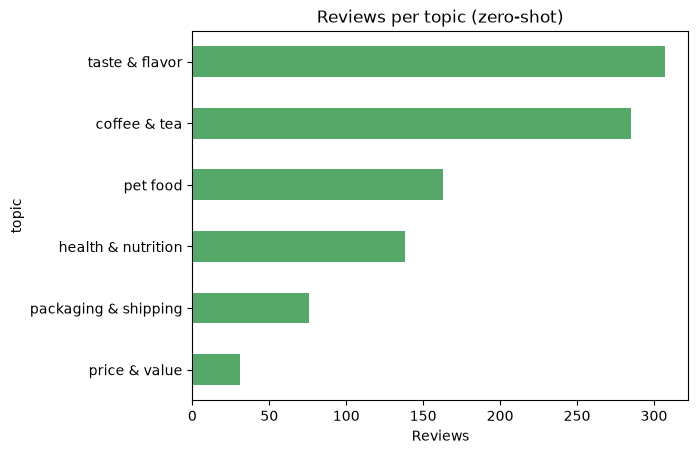

In [12]:
topic_labels = {
    "taste & flavor": "An Amazon review about how a food or drink tastes, its flavor, texture or freshness.",
    "price & value": "An Amazon review about the price, cost, value for money or a good deal.",
    "packaging & shipping": "An Amazon review about packaging, delivery, shipping, damaged boxes or expiration dates.",
    "health & nutrition": "An Amazon review about health, nutrition, ingredients, allergies, diet, sugar or calories.",
    "pet food": "An Amazon review of food or treats for a dog or cat and how the pet liked it.",
    "coffee & tea": "An Amazon review of coffee, tea, k-cups or other hot beverages.",
}
topics, topic_sims = zero_shot_classify(X_all, topic_labels)
df["topic"] = topics

ax = df["topic"].value_counts().plot.barh(color="#55A868", title="Reviews per topic (zero-shot)")
ax.invert_yaxis(); ax.set_xlabel("Reviews"); plt.show()

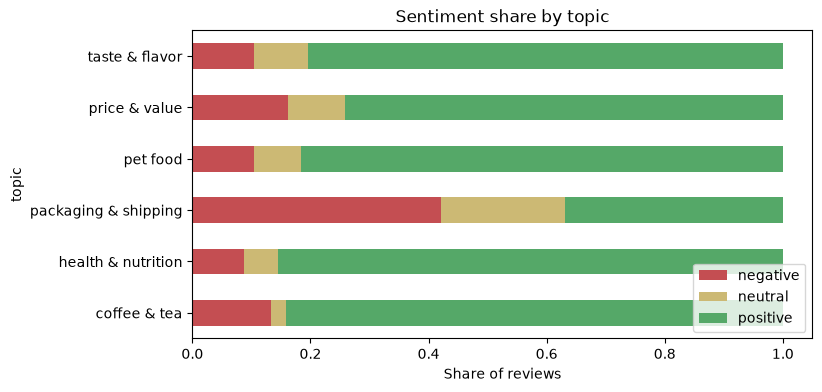

,count,mean
topic,,
packaging & shipping,76,2.84
price & value,31,4.06
taste & flavor,307,4.31
coffee & tea,285,4.33
pet food,163,4.35
health & nutrition,138,4.41


In [13]:
# Sentiment mix per topic (using true star-based sentiment)
mix = pd.crosstab(df["topic"], df["sentiment"], normalize="index")[["negative", "neutral", "positive"]]
mix.plot.barh(stacked=True, color=["#C44E52", "#CCB974", "#55A868"], figsize=(8, 4),
              title="Sentiment share by topic")
plt.xlabel("Share of reviews"); plt.legend(loc="lower right"); plt.show()

df.groupby("topic")["Score"].agg(["count", "mean"]).sort_values("mean").round(2)

In [14]:
# Most representative review for each topic
for i, topic in enumerate(topic_labels):
    row = df.iloc[topic_sims[:, i].argmax()]
    print(f"=== {topic} ===  ({row.Score}★)  {row.Summary}\n{row.Text[:250]}...\n")

=== taste & flavor ===  (5★)  Awesome
I can't find this in the stores and thought I would like it.  So I bought it and I can tell you that I love it.  It tastes just the way you're imagining it tastes when you read the ingredients... delish!...

=== price & value ===  (5★)  Excellent but Price?
I first heard about this on America's Test Kitchen where it won a blind taste test against a premium Italian brand and so we tried it, and verified that it was excellent and remains so to this day.  But the Amazon price is beyond comprehension, $18.8...

=== packaging & shipping ===  (1★)  Broken in a million pieces
Chips were broken into small pieces. Problem isn't amazon's, it's Stacy's. Stacy (or amazon) needs to pack the original box of six better, the bags move around too much. There was room for at least two more bags in the box.<br />Amazon packed the Sta...

=== health & nutrition ===  (5★)  Sugar-Free Brownies - Diabetes related issue
Extremely satisfied... got precisely what I ordered 

## 7. Supervised baseline for comparison

Zero-shot needs no labels. If we *do* have labels, a simple logistic regression on the very same embeddings gives an upper-bound reference. (Trained on 80%, evaluated on the held-out 20%.)

In [15]:
results = []
for name, data, labels, zs_col in [
    ("binary", binary_df, ["negative", "positive"], "zero_shot"),
    ("3-class", df, ["negative", "neutral", "positive"], "zero_shot_3"),
]:
    X = np.vstack(data["embedding"].values)
    y = data["sentiment"].values
    X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(
        X, y, data.index, test_size=0.2, stratify=y, random_state=42)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr)
    sup = clf.predict(X_te)
    zs = data.loc[idx_te, zs_col]
    for method, pred in [("zero-shot", zs), ("supervised (logreg)", sup)]:
        results.append({"task": name, "method": method,
                        "accuracy": accuracy_score(y_te, pred),
                        "macro_f1": f1_score(y_te, pred, average="macro")})

pd.DataFrame(results).round(3)

,task,method,accuracy,macro_f1
0,binary,zero-shot,0.946,0.901
1,binary,supervised (logreg),0.973,0.950
2,3-class,zero-shot,0.645,0.569
3,3-class,supervised (logreg),0.885,0.749


## 8. Classifying new reviews

In [16]:
def classify_review(text):
    """Return sentiment and topic for a new review using the zero-shot label embeddings."""
    emb = get_embeddings([text])
    out = {}
    for name, labels in [("sentiment", three_labels), ("topic", topic_labels)]:
        _, s = zero_shot_classify(emb, labels)
        out[name] = list(labels)[s.argmax()]
        out[f"{name}_scores"] = dict(zip(labels, s[0].round(3)))
    return out

new_reviews = [
    "Title: Delicious!; Content: These cookies are amazing, my kids ask for them every day.",
    "Title: Arrived crushed; Content: Half the bags were torn open and the box was soaked.",
    "Title: It's fine; Content: Tastes okay, nothing special. Probably won't reorder at this price.",
    "Title: My dog's favorite; Content: Our beagle goes crazy for these chews.",
]
for r in new_reviews:
    res = classify_review(r)
    print(f"{res['sentiment']:>8} | {res['topic']:<22} | {r}")

positive | health & nutrition     | Title: Delicious!; Content: These cookies are amazing, my kids ask for them every day.


negative | packaging & shipping   | Title: Arrived crushed; Content: Half the bags were torn open and the box was soaked.


 neutral | taste & flavor         | Title: It's fine; Content: Tastes okay, nothing special. Probably won't reorder at this price.


positive | pet food               | Title: My dog's favorite; Content: Our beagle goes crazy for these chews.


## 9. Conclusions

**Results on this run**

| Task | Method | Accuracy | Macro-F1 |
|---|---|---|---|
| Binary | Zero-shot, plain labels | 0.874 | 0.801 |
| Binary | Zero-shot, descriptive labels | 0.949 | 0.909 |
| Binary | Zero-shot, tuned threshold | 0.969 | 0.932 |
| Three-class | Zero-shot | 0.670 | 0.607 |
| Binary (20% test split) | Logistic regression | 0.973 | 0.950 |
| Three-class (20% test split) | Logistic regression | 0.885 | 0.749 |


- **Zero-shot classification with embeddings works with no training data.** Each class is defined only by a sentence; classification is a cosine-similarity lookup, so it is fast and cheap (one embedding call per review, plus one per class).
- **Label wording matters.** Descriptive prompts that look like the data (*"An Amazon review with a negative sentiment."*) beat bare label words, as the cookbook shows.
- **Thresholds matter on imbalanced data.** Using the similarity difference as a score and tuning the cut-off (on a small labeled sample) improves the minority negative class.
- **Neutral is hard.** Mixed 3-star reviews sit between the two poles in embedding space, so three-class accuracy is lower than binary. The zero-shot model over-predicts neutral (recall 0.76 but precision only 0.17), pulling many mildly worded 4–5★ reviews into it.
- **Topics add the "why".** Crossing zero-shot topics with sentiment shows which aspects (packaging & shipping reviews average 2.8★ vs. 4.3–4.4★ for taste, coffee/tea, pet food and health) drive negative reviews, which is directly actionable for product and operations teams.
- **When labels exist, use them.** A logistic regression on the same embeddings is a strong upgrade; zero-shot is ideal for bootstrapping, new categories, or when no labeled data is available.